In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("1315431420272_wine.csv")

df.head()

,class_label,class_name,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280,proline
0,1,Barolo,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,Barolo,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,Barolo,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,Barolo,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,Barolo,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst five rows:")
display(df.head())


Dataset shape: (178, 15)

Column names:
['class_label', 'class_name', 'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280', 'proline']

Missing values:
class_label             0
class_name              0
alcohol                 0
malic_acid              0
ash                     0
alcalinity_of_ash       0
magnesium               0
total_phenols           0
flavanoids              0
nonflavanoid_phenols    0
proanthocyanins         0
color_intensity         0
hue                     0
od280                   0
proline                 0
dtype: int64

First five rows:


,class_label,class_name,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280,proline
0,1,Barolo,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,Barolo,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,Barolo,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,Barolo,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,Barolo,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [6]:
# Extract class labels for LDA
y = df["class_label"].to_numpy()

# Extract the 13 numerical features
X = df.drop(columns=["class_label", "class_name"]).to_numpy()

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Number of features (D):", X.shape[1])
print("Number of classes:", len(np.unique(y)))

Feature matrix shape: (178, 13)
Label vector shape: (178,)
Number of features (D): 13
Number of classes: 3


In [7]:
# Calculate the mean and standard deviation of each feature
mean = np.mean(X, axis=0)
std = np.std(X, axis=0)

# Avoid division by zero
std[std == 0] = 1

# Standardize the dataset
X_scaled = (X - mean) / std

print("Standardized dataset shape:", X_scaled.shape)

print("\nMean of first five standardized features:")
print(np.mean(X_scaled, axis=0)[:5])

print("\nStandard deviation of first five standardized features:")
print(np.std(X_scaled, axis=0)[:5])

Standardized dataset shape: (178, 13)

Mean of first five standardized features:
[-8.38280756e-16 -1.19754394e-16 -8.37033314e-16 -3.99181312e-17
 -3.99181312e-17]

Standard deviation of first five standardized features:
[1. 1. 1. 1. 1.]


In [ ]:
#Implement PCA From Scratch

In [8]:
D = X_scaled.shape[1]  # Original number of dimensions
K = 2                  # Reduced number of dimensions

print("Original dimensions (D):", D)
print("Reduced dimensions (K):", K)

Original dimensions (D): 13
Reduced dimensions (K): 2


In [9]:
# Calculate the mean of each feature
pca_mean = np.mean(X_scaled, axis=0)

# Center the data
X_centered = X_scaled - pca_mean

print("Centered data shape:", X_centered.shape)

Centered data shape: (178, 13)


In [10]:
N = X_centered.shape[0]

# Calculate covariance matrix
cov_matrix = (X_centered.T @ X_centered) / (N - 1)

print("Covariance matrix shape:", cov_matrix.shape)

print("\nCovariance matrix:")
print(cov_matrix)

Covariance matrix shape: (13, 13)

Covariance matrix:
[[ 1.00564972  0.09493026  0.21273976 -0.31198788  0.27232816  0.29073446
   0.23815287 -0.15681042  0.13747022  0.549451   -0.07215255  0.07275191
   0.64735687]
 [ 0.09493026  1.00564972  0.16497228  0.29013035 -0.05488343 -0.3370606
  -0.41332866  0.29463237 -0.22199334  0.25039204 -0.56446685 -0.37079354
  -0.19309537]
 [ 0.21273976  0.16497228  1.00564972  0.44587209  0.28820583  0.12970824
   0.11572743  0.1872826   0.00970647  0.2603499  -0.07508874  0.00393333
   0.22488969]
 [-0.31198788  0.29013035  0.44587209  1.00564972 -0.0838039  -0.32292752
  -0.353355    0.36396647 -0.19844168  0.01883781 -0.27550299 -0.27833221
  -0.44308618]
 [ 0.27232816 -0.05488343  0.28820583 -0.0838039   1.00564972  0.21561254
   0.19688989 -0.25774204  0.23777643  0.20107967  0.05571118  0.06637684
   0.39557317]
 [ 0.29073446 -0.3370606   0.12970824 -0.32292752  0.21561254  1.00564972
   0.86944804 -0.45247731  0.61587304 -0.05544792  0.43613

In [13]:
# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors shape:")
print(eigenvectors.shape)

Eigenvalues:
[0.10396199 0.16972374 0.22706428 0.25232001 0.29051203 0.35046627
 0.55414147 0.64528221 0.85804868 0.92416587 1.45424187 2.51108093
 4.73243698]

Eigenvectors shape:
(13, 13)


In [14]:
# Sort eigenvalues in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]

# Rearrange eigenvalues and eigenvectors
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Sorted eigenvalues:")
print(eigenvalues)

Sorted eigenvalues:
[4.73243698 2.51108093 1.45424187 0.92416587 0.85804868 0.64528221
 0.55414147 0.35046627 0.29051203 0.25232001 0.22706428 0.16972374
 0.10396199]


In [15]:
# Select the top K eigenvectors
W_pca = eigenvectors[:, :K]

print("PCA projection matrix shape:", W_pca.shape)

PCA projection matrix shape: (13, 2)


In [16]:
# Project data into the reduced K-dimensional space
X_pca = X_centered @ W_pca

print("Original data shape:", X_scaled.shape)
print("Reduced data shape:", X_pca.shape)

Original data shape: (178, 13)
Reduced data shape: (178, 2)


In [18]:
# Reconstruct the original data from the reduced PCA data
X_pca_reconstructed = X_pca @ W_pca.T + pca_mean

print("Reconstructed data shape:", X_pca_reconstructed.shape)

Reconstructed data shape: (178, 13)


In [19]:
# Calculate Mean Squared Error (MSE)
pca_mse = np.mean((X_scaled - X_pca_reconstructed) ** 2)

# Calculate Sum of Squared Errors (SSE)
pca_sse = np.sum((X_scaled - X_pca_reconstructed) ** 2)

print("PCA Reconstruction MSE:", pca_mse)
print("PCA Reconstruction SSE:", pca_sse)

PCA Reconstruction MSE: 0.4459366164306474
PCA Reconstruction SSE: 1031.897330420518


In [20]:
# Calculate explained variance ratio
explained_variance_ratio = eigenvalues / np.sum(eigenvalues)

# Calculate total variance retained by the top K components
variance_retained = np.sum(explained_variance_ratio[:K])

print("Explained variance ratio of each component:")
print(explained_variance_ratio)

print(f"\nVariance retained by {K} components: {variance_retained * 100:.2f}%")

Explained variance ratio of each component:
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]

Variance retained by 2 components: 55.41%


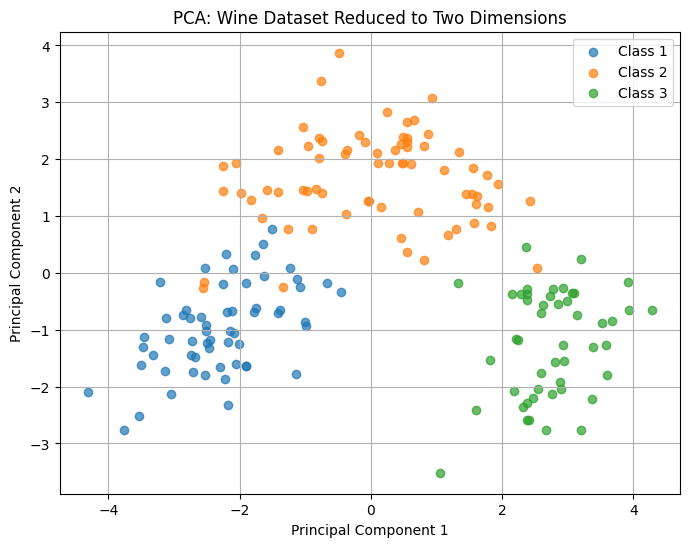

In [21]:
#Visualize the PCA results
plt.figure(figsize=(8, 6))

for label in np.unique(y):
    mask = y == label

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Class {label}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Wine Dataset Reduced to Two Dimensions")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
#Implement LDA from Scratch

In [25]:
D = X_scaled.shape[1]
C = len(np.unique(y))
K = 2

print("Original dimensions (D):", D)
print("Number of classes (C):", C)
print("Maximum LDA dimensions (C - 1):", C - 1)
print("Selected dimensions (K):", K)

assert 1 <= K <= min(D, C - 1)

Original dimensions (D): 13
Number of classes (C): 3
Maximum LDA dimensions (C - 1): 2
Selected dimensions (K): 2


In [26]:
# Calculate the overall mean
overall_mean = np.mean(X_scaled, axis=0)

print("Overall mean shape:", overall_mean.shape)
print("\nOverall mean:")
print(overall_mean)

Overall mean shape: (13,)

Overall mean:
[-8.38280756e-16 -1.19754394e-16 -8.37033314e-16 -3.99181312e-17
 -3.99181312e-17  0.00000000e+00 -3.99181312e-16  3.59263181e-16
 -1.19754394e-16  2.49488320e-17  1.99590656e-16  3.19345050e-16
 -1.59672525e-16]


In [27]:
# Initialize the within-class scatter matrix
S_W = np.zeros((D, D))

# Calculate the within-class scatter matrix
for label in np.unique(y):

    # Select samples belonging to this class
    X_class = X_scaled[y == label]

    # Calculate the mean of this class
    class_mean = np.mean(X_class, axis=0)

    # Center the class samples around their class mean
    X_class_centered = X_class - class_mean

    # Add the class scatter to the total within-class scatter
    S_W += X_class_centered.T @ X_class_centered

print("Within-class scatter matrix shape:", S_W.shape)
print("\nWithin-class scatter matrix:")
print(S_W)

Within-class scatter matrix shape: (13, 13)

Within-class scatter matrix:
[[ 69.97558741   1.58596418 -10.51666482  -6.31066486   0.2721888
    9.3862083    4.91173411  -1.69927008   6.35213739  23.04609931
    0.74176161  -1.52217996   8.4239853 ]
 [  1.58596418 125.15727532  12.28305855  19.56490069  -9.80929964
   -3.64603703  -1.48397152  12.8798202    4.73491503 -17.57941369
  -29.03818957  10.32402789 -16.53769124]
 [-10.51666482  12.28305855 154.49411548  93.00129061  30.96915038
   16.57405104  19.24807115  36.18736419   3.00448678   2.7101353
    6.51740068   9.85868883  -1.0205368 ]
 [ -6.31066486  19.56490069  93.00129061 126.34698725  11.94664714
    9.14565638  13.00065544  19.86550252   8.53736953  -2.31395511
   -2.26654675  16.74722444  -5.49440776]
 [  0.2721888   -9.80929964  30.96915038  11.94664714 155.85974967
   11.36293181   8.22623831 -28.42140827  27.99552069   9.42060069
    6.80103246  -4.87905935  18.63511314]
 [  9.3862083   -3.64603703  16.57405104   9.145

In [28]:
# Initialize the between-class scatter matrix
S_B = np.zeros((D, D))

# Calculate the between-class scatter matrix
for label in np.unique(y):

    # Select samples belonging to this class
    X_class = X_scaled[y == label]

    # Number of samples in this class
    N_class = X_class.shape[0]

    # Mean of this class
    class_mean = np.mean(X_class, axis=0)

    # Difference between class mean and overall mean
    mean_difference = (class_mean - overall_mean).reshape(D, 1)

    # Add the between-class scatter
    S_B += N_class * (mean_difference @ mean_difference.T)

print("Between-class scatter matrix shape:", S_B.shape)
print("\nBetween-class scatter matrix:")
print(S_B)

Between-class scatter matrix shape: (13, 13)

Between-class scatter matrix:
[[ 1.08024413e+02  1.52166913e+01  4.81716030e+01 -4.89111895e+01
   4.79298954e+01  4.20737915e+01  3.72413231e+01 -2.60561750e+01
   1.79800909e+01  7.42067274e+01 -1.35127627e+01  1.43992673e+01
   1.06158181e+02]
 [ 1.52166913e+01  5.28427247e+01  1.69170351e+01  3.17881710e+01
   9.49325389e-02 -5.60136885e+01 -7.16752011e+01  3.92701096e+01
  -4.40277363e+01  6.18988049e+01 -7.08724430e+01 -7.59544841e+01
  -1.76401893e+01]
 [ 4.81716030e+01  1.69170351e+01  2.35058845e+01 -1.40819314e+01
   2.00432807e+01  6.38430667e+00  1.23568451e+00 -3.03834475e+00
  -1.28644233e+00  4.33717969e+01 -1.98081069e+01 -9.16248978e+00
   4.08260117e+01]
 [-4.89111895e+01  3.17881710e+01 -1.40819314e+01  5.16530127e+01
  -2.67799369e+01 -6.63038269e+01 -7.55444905e+01  4.45565634e+01
  -4.36615463e+01  5.64824771e+00 -4.64974829e+01 -6.60120261e+01
  -7.29318460e+01]
 [ 4.79298954e+01  9.49325389e-02  2.00432807e+01 -2.677

In [29]:
# Calculate the pseudoinverse of the within-class scatter matrix
S_W_pinv = np.linalg.pinv(S_W)

# Construct the LDA discriminant matrix
lda_matrix = S_W_pinv @ S_B

# Calculate eigenvalues and eigenvectors
lda_eigenvalues, lda_eigenvectors = np.linalg.eig(lda_matrix)

# Remove numerical imaginary components
lda_eigenvalues = np.real_if_close(lda_eigenvalues).real
lda_eigenvectors = np.real_if_close(lda_eigenvectors).real

print("LDA eigenvalues:")
print(lda_eigenvalues)

print("\nLDA eigenvectors shape:")
print(lda_eigenvectors.shape)

LDA eigenvalues:
[ 0.00000000e+00  4.12846905e+00  9.08173944e+00  1.84650656e-15
 -6.68610857e-16 -2.46102408e-16 -2.46102408e-16 -2.04077544e-16
  1.97666487e-16  1.97666487e-16 -1.35830081e-17 -3.62644430e-18
  1.71439735e-16]

LDA eigenvectors shape:
(13, 13)


In [30]:
# Sort eigenvalues in descending order
sorted_indices = np.argsort(lda_eigenvalues)[::-1]

# Rearrange eigenvalues and eigenvectors
lda_eigenvalues = lda_eigenvalues[sorted_indices]
lda_eigenvectors = lda_eigenvectors[:, sorted_indices]

print("Sorted LDA eigenvalues:")
print(lda_eigenvalues)

Sorted LDA eigenvalues:
[ 9.08173944e+00  4.12846905e+00  1.84650656e-15  1.97666487e-16
  1.97666487e-16  1.71439735e-16  0.00000000e+00 -3.62644430e-18
 -1.35830081e-17 -2.04077544e-16 -2.46102408e-16 -2.46102408e-16
 -6.68610857e-16]


In [31]:
# Select the top K eigenvectors
W_lda = lda_eigenvectors[:, :K]

print("LDA projection matrix shape:", W_lda.shape)

LDA projection matrix shape: (13, 2)


In [32]:
# Center the data using the overall mean
X_lda_centered = X_scaled - overall_mean

# Project into the reduced LDA space
X_lda = X_lda_centered @ W_lda

print("Original data shape:", X_scaled.shape)
print("Reduced LDA data shape:", X_lda.shape)

Original data shape: (178, 13)
Reduced LDA data shape: (178, 2)


In [33]:
# Calculate the pseudoinverse of the LDA projection matrix
W_lda_pinv = np.linalg.pinv(W_lda)

# Reconstruct the original standardized data
X_lda_reconstructed = X_lda @ W_lda_pinv + overall_mean

print("Reconstructed LDA data shape:", X_lda_reconstructed.shape)

Reconstructed LDA data shape: (178, 13)


In [34]:
# Calculate reconstruction error
lda_mse = np.mean((X_scaled - X_lda_reconstructed) ** 2)

# Calculate total squared reconstruction error
lda_sse = np.sum((X_scaled - X_lda_reconstructed) ** 2)

print("LDA Reconstruction MSE:", lda_mse)
print("LDA Reconstruction SSE:", lda_sse)

LDA Reconstruction MSE: 0.7231340258395055
LDA Reconstruction SSE: 1673.3321357926156


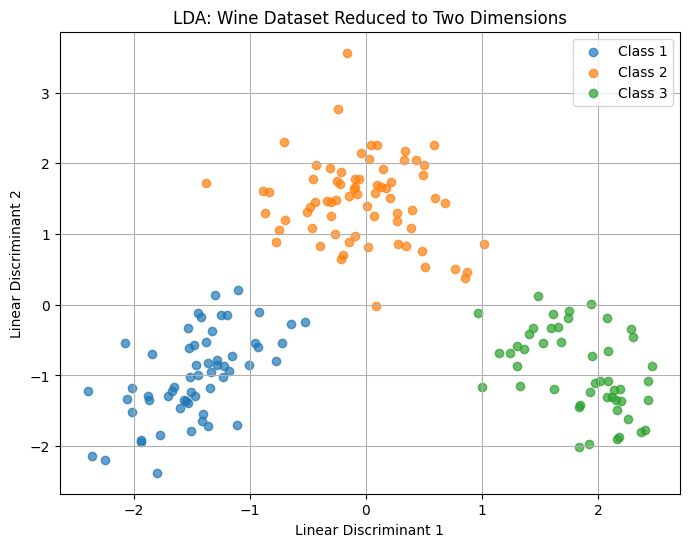

In [35]:
#Visualize the LDA results
plt.figure(figsize=(8, 6))

for label in np.unique(y):
    mask = y == label

    plt.scatter(
        X_lda[mask, 0],
        X_lda[mask, 1],
        label=f"Class {label}",
        alpha=0.7
    )

plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("LDA: Wine Dataset Reduced to Two Dimensions")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
#Compare PCA and LDA
results = pd.DataFrame({
    "Method": ["PCA", "LDA"],
    "Original Dimensions": [D, D],
    "Reduced Dimensions": [K, K],
    "Reconstruction MSE": [pca_mse, lda_mse],
    "Reconstruction SSE": [pca_sse, lda_sse]
})

display(results)

,Method,Original Dimensions,Reduced Dimensions,Reconstruction MSE,Reconstruction SSE
0,PCA,13,2,0.445937,1031.897330
1,LDA,13,2,0.723134,1673.332136


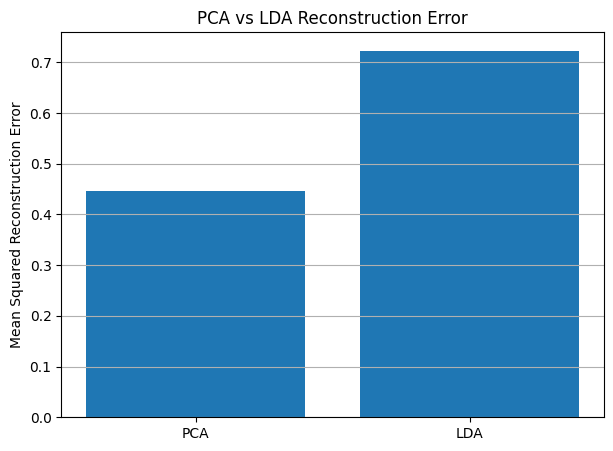

In [40]:
#Plot the reconstruction errors
plt.figure(figsize=(7, 5))

plt.bar(
    ["PCA", "LDA"],
    [pca_mse, lda_mse]
)

plt.ylabel("Mean Squared Reconstruction Error")
plt.title("PCA vs LDA Reconstruction Error")
plt.grid(axis="y")
plt.show()

In [38]:
#PCA reconstruction error for different K values
pca_errors = []

for k in range(1, D + 1):

    # Select the top k principal components
    W_k = eigenvectors[:, :k]

    # Reduce dimensions
    X_reduced = X_centered @ W_k

    # Reconstruct the data
    X_reconstructed = X_reduced @ W_k.T + pca_mean

    # Calculate reconstruction MSE
    mse = np.mean((X_scaled - X_reconstructed) ** 2)

    pca_errors.append(mse)

# Display results
for k, error in enumerate(pca_errors, start=1):
    print(f"K = {k:2d}, Reconstruction MSE = {error:.6f}")

K =  1, Reconstruction MSE = 0.638012
K =  2, Reconstruction MSE = 0.445937
K =  3, Reconstruction MSE = 0.334700
K =  4, Reconstruction MSE = 0.264010
K =  5, Reconstruction MSE = 0.198377
K =  6, Reconstruction MSE = 0.149019
K =  7, Reconstruction MSE = 0.106632
K =  8, Reconstruction MSE = 0.079825
K =  9, Reconstruction MSE = 0.057603
K = 10, Reconstruction MSE = 0.038303
K = 11, Reconstruction MSE = 0.020934
K = 12, Reconstruction MSE = 0.007952
K = 13, Reconstruction MSE = 0.000000


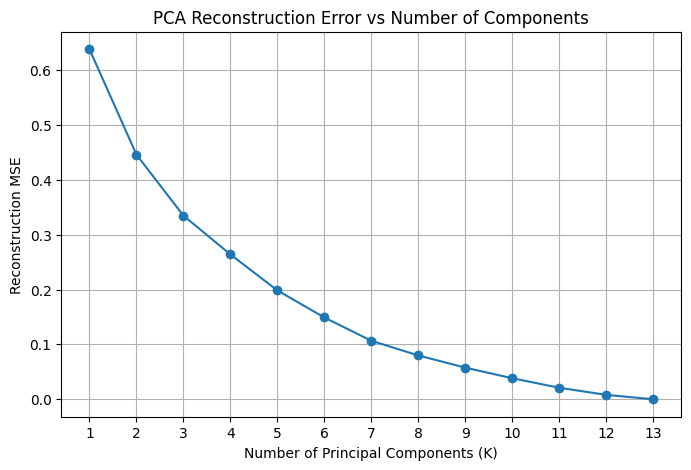

In [39]:
# Plot PCA reconstruction error against K

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, D + 1),
    pca_errors,
    marker="o"
)

plt.xlabel("Number of Principal Components (K)")
plt.ylabel("Reconstruction MSE")
plt.title("PCA Reconstruction Error vs Number of Components")
plt.xticks(range(1, D + 1))
plt.grid(True)
plt.show()